In [ ]:
from pathlib import Path
import sys

for _parent in (Path.cwd(), *Path.cwd().parents):
    if (_parent / "src" / "regression_module.py").exists():
        sys.path.insert(0, str(_parent / "src"))
        break


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math, copy
np.set_printoptions(precision=2)

In [2]:
from regression_module import load_house_data

def load_home_data():
    return load_house_data()


In [3]:
# load our dataset
X, y = load_home_data()
print(X.shape, y.shape)

(100, 4) (100,)


In [4]:
# now first of all rescale our all features
def z_score_normalization(X):
    X_mu = X.mean(axis=0)
    X_sigma = X.std(axis=0)
    X = (X - X_mu) / X_sigma
    return (X, X_mu, X_sigma)

In [5]:
def compute_cost(X, y, w, b):
    m = X.shape[0]
    cost_sum = 0
    for i in range(m):
        f_wb = np.dot(X[i], w) + b
        cost = (f_wb - y[i]) ** 2
        cost_sum += cost
    total_cost = cost_sum / (2 * m)
    return total_cost

In [6]:
def compute_gradient(X, y, w, b):
    m, n = X.shape
    dj_dw = np.zeros(n)
    dj_db = 0
    for i in range(m):
        err = (np.dot(X[i], w) + b) - y[i]
        for j in range(n):
            dj_dw[j] += err * X[i][j]
        dj_db += err
    dj_dw /= m
    dj_db /= m
    return dj_dw, dj_db

In [7]:
def gradient_descent(X, y, w_in, b_in, alpha, num_iters, compute_cost, compute_gradient):
    J_history = []
    w = copy.deepcopy(w_in)
    b = b_in
    for i in range(num_iters):
        dj_dw, dj_db = compute_gradient(X, y, w, b)
        w = w - alpha * dj_dw
        b = b - alpha * dj_db 
        if i<100000:
            J_history.append(compute_cost(X, y, w, b))
        if i % math.ceil(num_iters/10) == 0:
            print(
                f"Iteration {i:4}: Cost: {J_history[-1]:.4e}",
                f"w: {w}, b: {b:}"
            )
    return w, b, J_history

In [8]:
# now let's run it

In [9]:
X_train, X_mu, X_sigma = z_score_normalization(X)
w_init = np.zeros(X_train.shape[1])
b_init = 0
alpha = 0.1
iterations = 200

w_final, b_final, hist = gradient_descent(X_train, y, w_init, b_init, alpha, iterations, compute_cost, compute_gradient)

print(f"w, b found by gradient descent: {w_final}, {b_final}")

Iteration    0: Cost: 5.7326e+04 w: [ 8.92  3.02  3.33 -5.99], b: 36.223952
Iteration   20: Cost: 1.4628e+03 w: [ 69.96  -2.31  -6.62 -39.98], b: 322.6036378981157
Iteration   40: Cost: 3.4651e+02 w: [ 89.88 -11.66 -20.09 -40.87], b: 357.4207220523067
Iteration   60: Cost: 2.4970e+02 w: [100.02 -16.36 -26.48 -39.66], b: 361.6536666663715
Iteration   80: Cost: 2.2747e+02 w: [105.21 -18.82 -29.57 -38.79], b: 362.1682939116167
Iteration  100: Cost: 2.2173e+02 w: [107.86 -20.1  -31.1  -38.31], b: 362.23086057045475
Iteration  120: Cost: 2.2024e+02 w: [109.21 -20.77 -31.87 -38.05], b: 362.2384672155252
Iteration  140: Cost: 2.1985e+02 w: [109.9  -21.11 -32.26 -37.92], b: 362.2393920059855
Iteration  160: Cost: 2.1975e+02 w: [110.25 -21.29 -32.46 -37.85], b: 362.23950443891596
Iteration  180: Cost: 2.1972e+02 w: [110.43 -21.38 -32.56 -37.82], b: 362.2395181081355
w, b found by gradient descent: [110.51 -21.42 -32.61 -37.8 ], 362.23951974443713


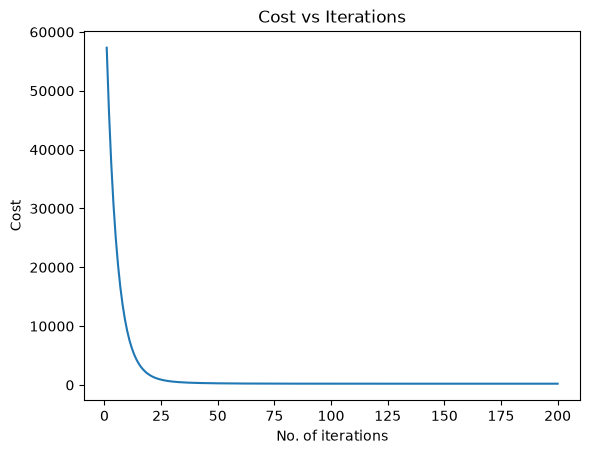

In [10]:
plt.plot(np.arange(1,201), hist)
plt.xlabel("No. of iterations")
plt.ylabel("Cost")
plt.title("Cost vs Iterations")
plt.show()

In [11]:
# now predict price of house with 1200sqft, 3 bedrooms,1 floor 40 years old
x = np.array([1200, 3, 1, 40])
x = (x - X_mu) / X_sigma
print(f"Price Prediction of the house: {np.dot(x,w_final)+b_final:.0f} thousand dollars")

Price Prediction of the house: 319 thousand dollars
